<a href="https://colab.research.google.com/github/gbrnkml/Klasifikasi-Hewan/blob/main/Klasifikasi_Hewan_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Klasifikasi Kucing dan Anjing

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers
from tensorflow.keras.preprocessing.image import ImageDataGenerator, load_img, img_to_array, array_to_img
import os
import tensorflow_hub as hub

Gunakan pre-trained model mobilenetv2

In [ ]:
image_size = (224, 224)
mobilenet_v2 = "https://tfhub.dev/google/tf2-preview/mobilenet_v2/feature_vector/4"

feature_extractor = hub.KerasLayer(mobilenet_v2,
                                   input_shape=image_size + (3,),
                                   trainable=False)

Mount google drive untuk mendapatkan dataset

In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Copy dataset dari google drive ke google colab environment

In [ ]:
import shutil

drive_folder_path = '/content/drive/MyDrive/Dataset'

colab_folder_path = '/content/Dataset'

shutil.copytree(drive_folder_path, colab_folder_path)

'/content/Dataset'

In [ ]:
import zipfile

nama_file_zip = '/content/Dataset/archive.zip'

direktori_ekstraksi = '/content/Dataset kucing dan anjing'

with zipfile.ZipFile(nama_file_zip, 'r') as zip_ref:
    zip_ref.extractall(direktori_ekstraksi)

# Pre-processing image

Cek total keseluruhan dataset pada folder training dan validation

In [ ]:
training_dir = '/content/Dataset kucing dan anjing/training_set/training_set/'
validation_dir = '/content/Dataset kucing dan anjing/test_set/test_set/'

for folder in os.listdir(training_dir):
    item_path = os.path.join(training_dir, folder)

    print(f'Total foto training {folder}: {len(os.listdir(item_path))}')

print('\n')

for folder in os.listdir(validation_dir):
    item_path = os.path.join(validation_dir, folder)

    print(f'Total foto validasi {folder}: {len(os.listdir(item_path))}')

Total foto training cats: 4001
Total foto training dogs: 4006


Total foto validasi cats: 1012
Total foto validasi dogs: 1013


Cek sampel foto tiap kategori

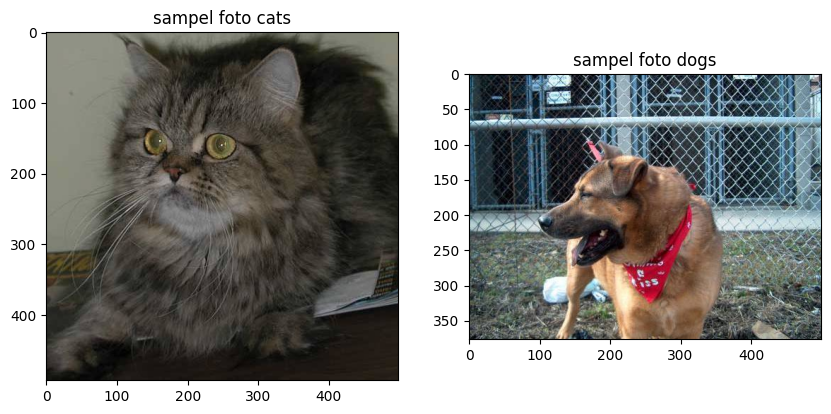

In [ ]:
import matplotlib.pyplot as plt

fig, axs = plt.subplots(1, 2, figsize=(2 * 5, 5))
for i, folder in enumerate(os.listdir(training_dir)):
    item_path = os.path.join(training_dir, folder)
    sample_image = load_img(f'{os.path.join(item_path, os.listdir(item_path)[0])}')
    axs[i].imshow(sample_image)
    axs[i].set_title(f'sampel foto {folder}')
plt.show()

Cek pixel shape dari setiap foto

In [ ]:
for folder in os.listdir(training_dir):
    item_path = os.path.join(training_dir, folder)
    sample_image = load_img(f'{os.path.join(item_path, os.listdir(item_path)[0])}')
    sample_array = img_to_array(sample_image)
    print(f'Setiap foto {folder} memiliki pixel : {sample_array.shape}')

Setiap foto cats memiliki pixel : (493, 499, 3)
Setiap foto dogs memiliki pixel : (376, 500, 3)


Memberikan pelabelan berdasarkan nama folder menggunakan ImageDataGenerator(), sekaligus menormalisasikan dan augmentasi dataset training

In [ ]:
def train_val_generators(train_dir, val_dir):
  train_datagen = ImageDataGenerator(rescale=1.0/255.0,
                                     rotation_range=30,
                                     width_shift_range=0.3,
                                     height_shift_range=0.2,
                                     shear_range=0.3,
                                     zoom_range=0.2,
                                     horizontal_flip=True,
                                     fill_mode='nearest')

  train_generator = train_datagen.flow_from_directory(directory=train_dir,
                                                      batch_size=64,
                                                      class_mode='categorical',
                                                      shuffle=True,
                                                      target_size=image_size)

  val_datagen = ImageDataGenerator(rescale=1.0/255.0)

  val_generator = val_datagen.flow_from_directory(directory=val_dir,
                                                  batch_size=32,
                                                  class_mode='categorical',
                                                  target_size=image_size)

  return train_generator, val_generator

train_generator, val_generator = train_val_generators(training_dir, validation_dir)

Found 8005 images belonging to 2 classes.
Found 2023 images belonging to 2 classes.


# Building Model

Mendefine arsitektur model

In [ ]:
def create_model():

  model = tf.keras.models.Sequential([
      feature_extractor,
      layers.Dense(256, activation='relu'),
      layers.Dense(2, activation='sigmoid')
  ])

  model.compile(optimizer = tf.keras.optimizers.Adam(learning_rate = 0.001),
                loss = 'binary_crossentropy',
                metrics = ['accuracy'])
  return model

Melihat ringkasan arsitektur model

In [ ]:
model = create_model()

model.summary()

Model: "sequential_2"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 keras_layer (KerasLayer)    (None, 1280)              2257984   
                                                                 
 dense_4 (Dense)             (None, 256)               327936    
                                                                 
 dense_5 (Dense)             (None, 2)                 514       
                                                                 
Total params: 2586434 (9.87 MB)
Trainable params: 328450 (1.25 MB)
Non-trainable params: 2257984 (8.61 MB)
_________________________________________________________________


In [ ]:
filepath = 'my_model.h5'

checkpoint = tf.keras.callbacks.ModelCheckpoint(filepath,
                    monitor="val_loss", mode="min",
                    save_best_only=True, verbose=1)

Training model

In [ ]:
model.fit(train_generator,
          epochs = 5,
          verbose = 2,
          validation_data = val_generator,
          callbacks=[checkpoint])

Epoch 1/5

Epoch 1: val_loss improved from inf to 0.03490, saving model to my_model.h5
126/126 - 282s - loss: 0.0978 - accuracy: 0.9679 - val_loss: 0.0349 - val_accuracy: 0.9871 - 282s/epoch - 2s/step
Epoch 2/5

Epoch 2: val_loss improved from 0.03490 to 0.03411, saving model to my_model.h5
126/126 - 271s - loss: 0.0831 - accuracy: 0.9670 - val_loss: 0.0341 - val_accuracy: 0.9867 - 271s/epoch - 2s/step
Epoch 3/5

Epoch 3: val_loss did not improve from 0.03411
126/126 - 276s - loss: 0.0707 - accuracy: 0.9719 - val_loss: 0.0351 - val_accuracy: 0.9862 - 276s/epoch - 2s/step
Epoch 4/5

Epoch 4: val_loss did not improve from 0.03411
126/126 - 271s - loss: 0.0651 - accuracy: 0.9749 - val_loss: 0.0379 - val_accuracy: 0.9867 - 271s/epoch - 2s/step
Epoch 5/5

Epoch 5: val_loss did not improve from 0.03411
126/126 - 274s - loss: 0.0645 - accuracy: 0.9759 - val_loss: 0.0513 - val_accuracy: 0.9817 - 274s/epoch - 2s/step


# Evaluate model

Plotting loss, val_loss dan acc, val_acc

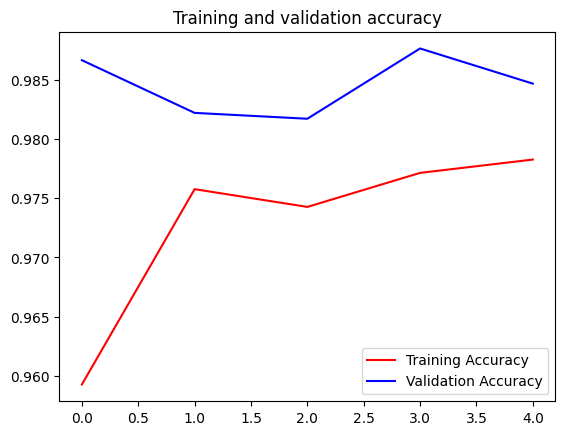

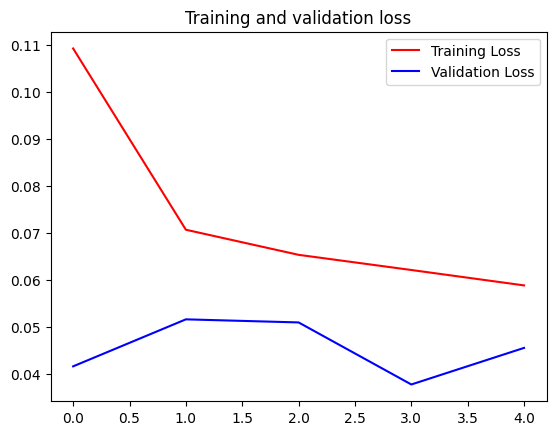

In [ ]:
acc=model.history.history['accuracy']
val_acc=model.history.history['val_accuracy']
loss=model.history.history['loss']
val_loss=model.history.history['val_loss']

epochs=range(len(acc))

plt.plot(epochs, acc, 'r', label = "Training Accuracy")
plt.plot(epochs, val_acc, 'b', label = "Validation Accuracy")
plt.title('Training and validation accuracy')
plt.legend()

plt.show()
print('')

plt.plot(epochs, loss, 'r', label = "Training Loss")
plt.plot(epochs, val_loss, 'b', label = "Validation Loss")
plt.title('Training and validation loss')
plt.legend()

plt.show()

Memberikan pelabelan dataset test berdasarkan nama folder menggunakan ImageDataGenerator()

In [ ]:
test_dir = '/content/Dataset kucing dan anjing/test_set/test_set/'

test_datagen = ImageDataGenerator(rescale=1.0/255.0)

test_generator = test_datagen.flow_from_directory(directory=test_dir,
                                                  batch_size=32,
                                                  class_mode='categorical',
                                                  target_size=image_size)

Found 2023 images belonging to 2 classes.


Evaluasi model menggunakan dataset testing

In [ ]:
model.evaluate(test_generator)

64/64 [==============================] - 40s 623ms/step - loss: 0.0513 - accuracy: 0.9817


[0.05129973217844963, 0.9817103147506714]

Melakukan prediksi menggunakan foto yang diupload

Saving WhatsApp Image 2024-01-16 at 20.36.23_a0ac9300.jpg to WhatsApp Image 2024-01-16 at 20.36.23_a0ac9300.jpg
1/1 [==============================] - 0s 54ms/step


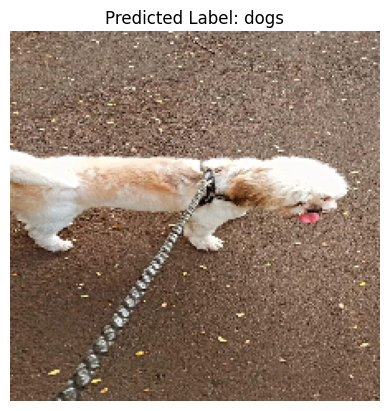

In [ ]:
from google.colab import files
import numpy as np
from tensorflow.keras.preprocessing import image
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

uploaded = files.upload()

for fn in uploaded.keys():

  path = fn
  image = image.load_img(path, target_size=image_size)
  img = img_to_array(image)
  img = np.expand_dims(img, axis=0)
  img = preprocess_input(img)

  predictions = model.predict(img)
  predicted_class_index = np.argmax(predictions)

  class_indices = train_generator.class_indices
  labels = list(class_indices.keys())
  predicted_class_label = labels[predicted_class_index]

  plt.imshow(image)

  plt.axis('off')
  plt.title(f'Predicted Label: {predicted_class_label}')

  plt.show()